<a href="https://colab.research.google.com/github/aparnapandey26/Cat_Dog_Classifier-/blob/main/Cat_Dog_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded = files.upload()

Saving imge.zip to imge.zip


In [3]:
print(list(uploaded.keys()))

['imge.zip']


In [4]:
!unzip -q "/content/image.zip" -d "/content/cat_dog_data"

print("Dataset extracted successfully!")

unzip:  cannot find or open /content/image.zip, /content/image.zip.zip or /content/image.zip.ZIP.
Dataset extracted successfully!


In [5]:
import os
print(os.listdir("/content"))

['.config', 'imge.zip', 'sample_data']


In [6]:
import zipfile
import os

zip_path = "/content/imge.zip"
extract_path = "/content/cat_dog_data"

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_path)

print("Dataset extracted successfully!")

for root, dirs, files in os.walk(extract_path):
    print(root, "->", len(files), "files")

Dataset extracted successfully!
/content/cat_dog_data -> 0 files
/content/cat_dog_data/test_set -> 0 files
/content/cat_dog_data/test_set/dogs -> 1013 files
/content/cat_dog_data/test_set/cats -> 1012 files
/content/cat_dog_data/__MACOSX -> 2 files
/content/cat_dog_data/__MACOSX/test_set -> 2 files
/content/cat_dog_data/__MACOSX/test_set/dogs -> 1013 files
/content/cat_dog_data/__MACOSX/test_set/cats -> 1012 files
/content/cat_dog_data/__MACOSX/training_set -> 2 files
/content/cat_dog_data/__MACOSX/training_set/dogs -> 4006 files
/content/cat_dog_data/__MACOSX/training_set/cats -> 4001 files
/content/cat_dog_data/training_set -> 0 files
/content/cat_dog_data/training_set/dogs -> 4006 files
/content/cat_dog_data/training_set/cats -> 4001 files


In [7]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten, Conv2D, AveragePooling2D

In [8]:
train_dir = "/content/cat_dog_data/training_set"
validation_dir = "/content/cat_dog_data/test_set"

print("Training folders:", os.listdir(train_dir))
print("Testing folders:", os.listdir(validation_dir))

Training folders: ['dogs', 'cats']
Testing folders: ['dogs', 'cats']


In [9]:
# training dataset

train_dir = keras.utils.image_dataset_from_directory(
    directory="/content/cat_dog_data/training_set",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

# Validation dataset
validation_dir = keras.utils.image_dataset_from_directory(
    directory="/content/cat_dog_data/test_set",
    labels="inferred",
    label_mode="int",
    batch_size=32,
    image_size=(256, 256)
)

Found 8005 files belonging to 2 classes.
Found 2023 files belonging to 2 classes.


In [10]:
def normalize(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_dir = train_dir.map(normalize)
validation_dir = validation_dir.map(normalize)

In [11]:
for images, labels in train_dir.take(1):
    print("Image shape:", images.shape)
    print("Minimum pixel value:", tf.reduce_min(images).numpy())
    print("Maximum pixel value:", tf.reduce_max(images).numpy())
    print("Labels shape:", labels.shape)

Image shape: (32, 256, 256, 3)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Labels shape: (32,)


In [20]:

model=Sequential()

model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu',input_shape=(256,256,3)))
model.add(AveragePooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(AveragePooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(AveragePooling2D(pool_size=(2,2),strides=2,padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dense(64,activation='relu'))
model.add(Dense(1,activation='sigmoid'))


In [25]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_3             │ (None, 127, 127, 32)   │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_4             │ (None, 62, 62, 64)     │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_5             │ (None, 30, 30, 128)    │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 115200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │    14,745,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,541,893 (169.91 MB)

 Trainable params: 14,847,297 (56.64 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 29,694,596 (113.28 MB)

In [26]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [68]:
history = model.fit(train_dir, validation_data=validation_dir, epochs=10)

Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 15s 58ms/step - accuracy: 0.9984 - loss: 0.0069 - val_accuracy: 0.6708 - val_loss: 2.8708
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 15s 58ms/step - accuracy: 0.9976 - loss: 0.0100 - val_accuracy: 0.6762 - val_loss: 2.8205
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.9940 - loss: 0.0219 - val_accuracy: 0.6782 - val_loss: 2.5889
Epoch 4/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 15s 59ms/step - accuracy: 0.9960 - loss: 0.0175 - val_accuracy: 0.6653 - val_loss: 2.2820
Epoch 5/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 15s 61ms/step - accuracy: 0.9989 - loss: 0.0059 - val_accuracy: 0.6723 - val_loss: 2.7253
Epoch 6/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 15s 59ms/step - accuracy: 0.9981 - loss: 0.0071 - val_accuracy: 0.6649 - val_loss: 2.7417
Epoch 7/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 21s 59ms/step - accuracy: 0.9949 - loss: 0.0218 - val_accuracy: 0.6718 - val_loss: 2.5424
Epoch 8/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 15s 59ms/step - accuracy: 0.9983 - loss: 0.0089 - 

In [88]:
# Evaluate the model using the preprocessed validation dataset pipeline 'validation_dir'
test_loss, test_accuracy = model.evaluate(validation_dir)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

64/64 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - accuracy: 0.6629 - loss: 2.8265
Test Loss: 2.826542615890503
Test Accuracy: 0.6628769040107727


test_img_Shape (553, 555, 3)
test_img_Shape (256, 256, 3)
test_input_Shape (1, 256, 256, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step


array([[1.]], dtype=float32)

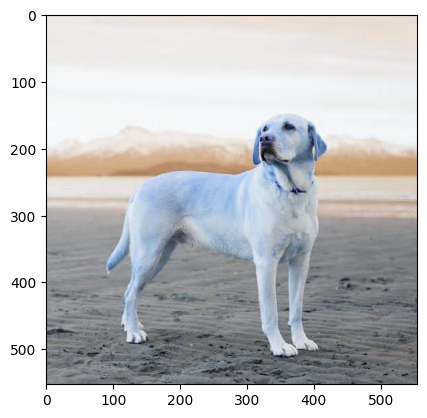

In [85]:
import cv2
import matplotlib.pyplot as plt
test_img=cv2.imread('/content/dog.jpeg')
plt.imshow(test_img)
print("test_img_Shape",test_img.shape)
test_img=cv2.resize(test_img,(256,256))
print("test_img_Shape",test_img.shape)
test_input=test_img.reshape((1,256,256,3))
print("test_input_Shape",test_input.shape)
model.predict(  test_input  )

test_img_Shape (675, 1200, 3)
test_img_Shape (256, 256, 3)
test_input_Shape (1, 256, 256, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 101ms/step


array([[0.]], dtype=float32)

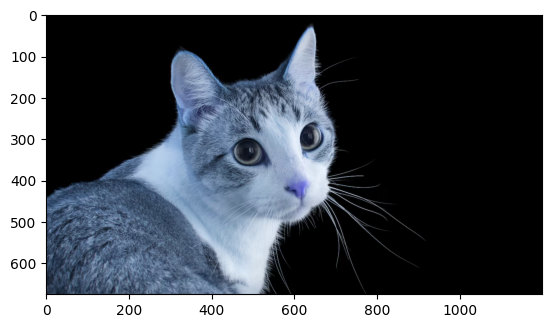

In [86]:
import cv2
import matplotlib.pyplot as plt
test_img=cv2.imread('/content/cats.jpg.avif')
plt.imshow(test_img)
print("test_img_Shape",test_img.shape)
test_img=cv2.resize(test_img,(256,256))
print("test_img_Shape",test_img.shape)
test_input=test_img.reshape((1,256,256,3))
print("test_input_Shape",test_input.shape)
model.predict(  test_input  )